# Retail Sales – High-Profit Order Prediction
Apply, evaluate and compare **5 algorithms** (KNN, SVM, Naive Bayes, Logistic Regression, Gradient Boosting) on the **full cleaned dataset** using **10-Fold Stratified Cross-Validation**.

**Task (classification):** predict whether a sales transaction is a **High-Profit order** (`Profit` above the median) using only information known when the order is placed (customer, product, price, discount, channel, payment, shipping, date/time).

**Why this target?** I tested the other natural targets: `Return_Flag` (returned or not) and `Customer_Rating` (satisfied or not) cannot be predicted from these columns (ROC-AUC ≈ 0.50, i.e. random guessing), so comparing algorithms on them would be meaningless. `Profit` is clearly predictable. `Sales_Amount`, `Cost_Amount` and `Profit` are **not** used as inputs (that would leak the answer).

## 1. Load the dataset
Put `archive (2).zip` (or the CSV) in the same folder as this notebook, or edit `DATA_PATH`.

In [1]:
import zipfile, glob, os

DATA_PATH = 'archive (2).zip'      # zip or the 'Sales_transactions_2022_2025.csv' file

if not os.path.exists(DATA_PATH):
    try:                                   # Google Colab: ask for the file
        from google.colab import files
        DATA_PATH = list(files.upload().keys())[0]
    except ImportError:
        raise FileNotFoundError(f'{DATA_PATH} not found - put it next to this notebook or edit DATA_PATH')

if DATA_PATH.endswith('.zip'):
    with zipfile.ZipFile(DATA_PATH) as f:
        f.extractall('data')
    csv_path = [p for p in glob.glob('data/**/*.csv', recursive=True) if 'transactions' in p.lower()][0]
else:
    csv_path = DATA_PATH
print('Using:', csv_path)

Using: data\Sales_transactions_2022_2025.csv


In [2]:
import pandas as pd, numpy as np, re, time, warnings
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

raw = pd.read_csv(csv_path)
print(raw.shape)
raw.head()

(18045, 36)


,Transaction_ID,Order_ID,Customer_ID,Customer_Name,Customer_Age,Customer_Gender,Customer_Segment,Order_Date,Order_Time,Sales_Channel,...,Order_Status,Shipping_Method,Delivery_Days,Return_Flag,Return_Reason,Sales_Representative,Promotion_Code,Customer_Rating,Inventory_Level,Order_Year
0,T02016694,O0116694,C01482,Sophia Smith,28.0,Male,Consumer,2022-10-06,11:30:55,Online,...,Completed,Standard,4.0,No,NaN,James Anderson,SAVE10,4.0,81.0,2022
1,T02016374,O0108187,C01591,Hannah King,46.0,Female,Consumer,2024-06-03,17:06:29,Online,...,Completed,Standard,6.0,No,NaN,Ella Lewis,NaN,5.0,123.0,2024
2,T02004099,O0104099,C04140,Emma Wilson,42.0,Male,Consumer,2024-12-19,08:22:11,Online,...,Shipped,Standard,4.0,No,NaN,Liam Davis,NaN,4.0,93.0,2024
3,T02010280,O0110280,C03663,Daniel Clark,18.0,Male,Corporate,2025-10-05,14:32:43,B2B Portal,...,Completed,Next Day,2.0,No,NaN,Grace Harris,HOLIDAY20,NaN,59.0,2025
4,T02012685,O0112685,C02749,Sophia Smith,37.0,Male,Returning Customer,2022-09-13,14:55:16,B2B Portal,...,Completed,Express,2.0,No,NaN,Sophia Brown,NaN,2.0,56.0,2022


## 2. Data cleaning
This dataset is intentionally messy. Problems found and fixed here:
- 45 duplicate transactions
- inconsistent spelling/case in categories (`male`/`Male`/`FEMALE`, `DebitCard`/`Debit Card`, `electronics`/`Electronics`)
- invalid values: quantity ≤ 0, discount > 30 %, ages above 100
- missing values (age, gender, payment method, delivery days, inventory, …) – these are filled **inside the pipeline** (per training fold, no leakage)

In [3]:
df = raw.copy()
n0 = len(df)

# 1) duplicates
df = df.drop_duplicates(subset='Transaction_ID').reset_index(drop=True)

# 2) standardise text categories: strip spaces, ignore case/punctuation, keep most frequent spelling
def standardize(s):
    s = s.astype(object).where(s.notna(), np.nan)
    key = s.map(lambda v: re.sub(r'[^a-z0-9]', '', v.lower()) if isinstance(v, str) else np.nan)
    clean = s.map(lambda v: re.sub(r'\s+', ' ', v.strip()) if isinstance(v, str) else np.nan)
    canon = clean.groupby(key).agg(lambda x: x.value_counts().index[0])
    return key.map(canon)

for c in ['Customer_Gender','Customer_Segment','Sales_Channel','Country','Product_Category',
          'Product_Subcategory','Payment_Method','Shipping_Method','Promotion_Code']:
    df[c] = standardize(df[c])
df['Promotion_Code'] = df['Promotion_Code'].fillna('None')      # NaN here means "no promotion"

# 3) invalid values
bad = (df.Quantity <= 0) | (df.Discount_Percentage > 30) | (df.Sales_Amount <= 0)
df = df[~bad].reset_index(drop=True)
df.loc[(df.Customer_Age < 15) | (df.Customer_Age > 100), 'Customer_Age'] = np.nan

# 4) date/time features
dt = pd.to_datetime(df['Order_Date'])
df['Order_Month'] = dt.dt.month
df['Order_DayOfWeek'] = dt.dt.dayofweek
df['Order_Hour'] = pd.to_datetime(df['Order_Time'], format='%H:%M:%S').dt.hour

# 5) target: High-Profit order
profit_median = float(df['Profit'].median())
df['High_Profit'] = (df['Profit'] > profit_median).astype(int)

print(f'Rows: {n0} -> {len(df)}  (removed {n0-len(df)})')
print('Profit median used as threshold:', round(profit_median, 2))
print(df['High_Profit'].value_counts())
for c in ['Customer_Gender','Product_Category','Payment_Method']:
    print(c, df[c].unique().tolist())

Rows: 18045 -> 17989  (removed 56)
Profit median used as threshold: 40.15
High_Profit
0    8995
1    8994
Name: count, dtype: int64
Customer_Gender ['Male', 'Female', 'Non-binary', nan]
Product_Category ['Electronics', 'Office Supplies', 'Furniture', 'Appliances']
Payment_Method ['Credit Card', 'Debit Card', 'PayPal', 'Apple Pay', 'Cash', 'Bank Transfer', nan]


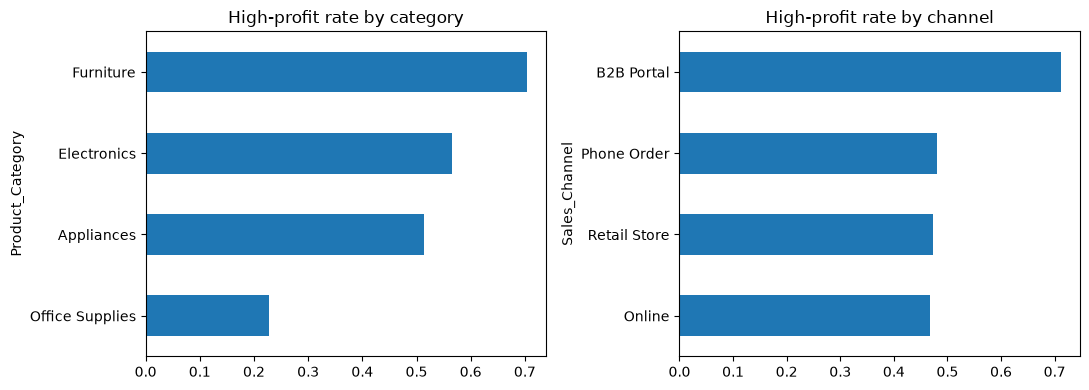

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
df.groupby('Product_Category')['High_Profit'].mean().sort_values().plot(kind='barh', ax=ax[0], title='High-profit rate by category')
df.groupby('Sales_Channel')['High_Profit'].mean().sort_values().plot(kind='barh', ax=ax[1], title='High-profit rate by channel')
plt.tight_layout(); plt.show()

## 3. Features and preprocessing
Identifiers/names, the outcome columns (`Sales_Amount`, `Cost_Amount`, `Profit`) and after-the-sale columns (`Order_Status`, `Return_*`, `Customer_Rating`, `Delivery_Days`) are excluded. Inside a Pipeline: median-impute + scale numeric columns, most-frequent-impute + one-hot encode categorical columns.

In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

num_cols = ['Customer_Age', 'Quantity', 'Unit_Price', 'Discount_Percentage',
            'Inventory_Level', 'Order_Month', 'Order_DayOfWeek', 'Order_Hour']
cat_cols = ['Customer_Gender', 'Customer_Segment', 'Sales_Channel', 'Country', 'Product_Category',
            'Product_Subcategory', 'Payment_Method', 'Shipping_Method', 'Promotion_Code']

X = df[num_cols + cat_cols].copy()
y = df['High_Profit']
print(X.shape, '| missing values per column:')
print(X.isna().sum()[X.isna().sum() > 0])

def make_preprocessor():
    return ColumnTransformer([
        ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), num_cols),
        ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                          ('oh', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat_cols),
    ])

(17989, 17) | missing values per column:
Customer_Age       218
Inventory_Level    198
Customer_Gender    162
Payment_Method     144
dtype: int64


## 4. Define the 5 algorithms
The dataset is small enough (~18,000 rows) to use the **RBF-kernel SVM**. If it is too slow on your computer set `USE_RBF_SVM = False` to use a Linear SVM.

In [6]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC, LinearSVC
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier

USE_RBF_SVM = True

models = {
    'KNN': KNeighborsClassifier(n_neighbors=15, n_jobs=-1),
    'SVM': SVC(kernel='rbf', C=1.0) if USE_RBF_SVM else LinearSVC(C=1.0, max_iter=5000),
    'Naive Bayes': GaussianNB(),
    'Logistic Regression': LogisticRegression(max_iter=2000),
    'Gradient Boosting': HistGradientBoostingClassifier(random_state=42),
}

## 5. 10-Fold Cross-Validation on the FULL dataset

In [7]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
scoring = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

results, fold_scores = [], {}
for name, model in models.items():
    start = time.time()
    pipe = Pipeline([('prep', make_preprocessor()), ('model', model)])
    r = cross_validate(pipe, X, y, cv=cv, scoring=scoring, n_jobs=-1)
    fold_scores[name] = r['test_accuracy']
    row = {'Model': name}
    for m in scoring:
        row[m] = r[f'test_{m}'].mean()
        row[m + '_std'] = r[f'test_{m}'].std()
    row['Time (s)'] = time.time() - start
    results.append(row)
    print(f"{name:20s} acc={row['accuracy']:.4f}  f1={row['f1']:.4f}  auc={row['roc_auc']:.4f}  ({row['Time (s)']:.1f}s)")

KNN                  acc=0.8616  f1=0.8502  auc=0.9466  (30.4s)
SVM                  acc=0.9540  f1=0.9539  auc=0.9925  (87.5s)
Naive Bayes          acc=0.7881  f1=0.7792  auc=0.8709  (1.8s)
Logistic Regression  acc=0.9491  f1=0.9486  auc=0.9840  (2.5s)
Gradient Boosting    acc=0.9739  f1=0.9739  auc=0.9969  (11.9s)


## 6. Compare results

In [8]:
res = pd.DataFrame(results).set_index('Model')
summary = res[['accuracy', 'precision', 'recall', 'f1', 'roc_auc', 'Time (s)']].round(4)
summary.sort_values('f1', ascending=False)

,accuracy,precision,recall,f1,roc_auc,Time (s)
Model,,,,,,
Gradient Boosting,0.9739,0.9716,0.9763,0.9739,0.9969,11.8882
SVM,0.9540,0.9567,0.9511,0.9539,0.9925,87.4860
Logistic Regression,0.9491,0.9582,0.9393,0.9486,0.9840,2.4862
KNN,0.8616,0.9259,0.7861,0.8502,0.9466,30.4281
Naive Bayes,0.7881,0.8137,0.7479,0.7792,0.8709,1.7775


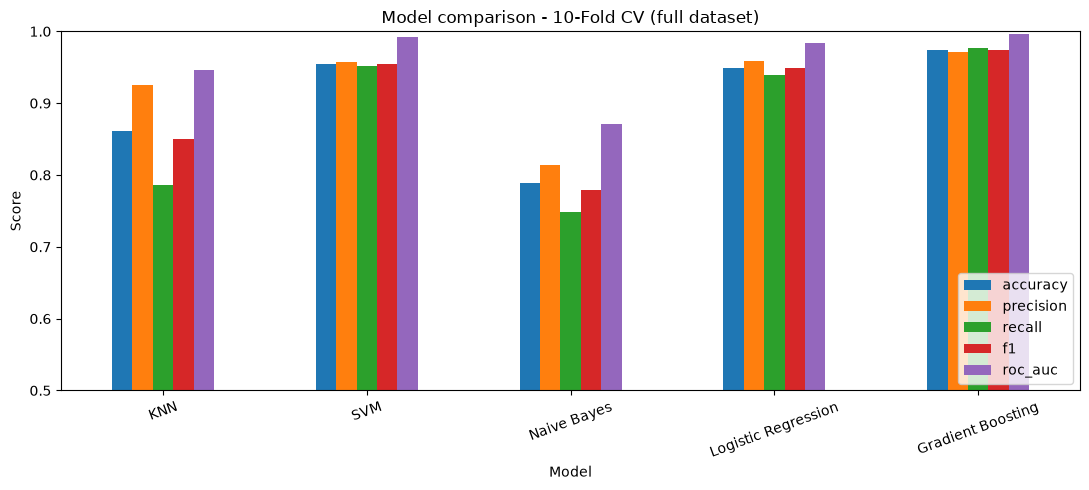

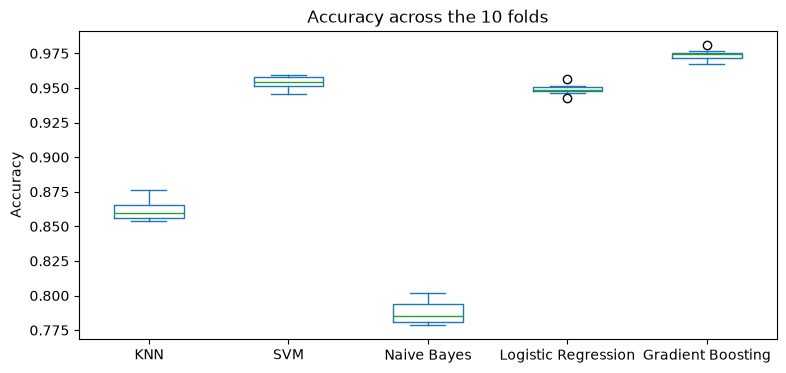

In [9]:
ax = res[['accuracy', 'precision', 'recall', 'f1', 'roc_auc']].plot(kind='bar', figsize=(11, 5), ylim=(0.5, 1.0))
ax.set_title('Model comparison - 10-Fold CV (full dataset)'); ax.set_ylabel('Score')
plt.xticks(rotation=20); plt.legend(loc='lower right'); plt.tight_layout(); plt.show()

pd.DataFrame(fold_scores).plot(kind='box', figsize=(9, 4), title='Accuracy across the 10 folds')
plt.ylabel('Accuracy'); plt.show()

In [10]:
best = summary['f1'].idxmax()
print(f"Best model by F1: {best}")
print(f"Accuracy {summary.loc[best,'accuracy']:.4f} | F1 {summary.loc[best,'f1']:.4f} | ROC-AUC {summary.loc[best,'roc_auc']:.4f}")
summary.to_csv('retail_model_comparison_results.csv')

Best model by F1: Gradient Boosting
Accuracy 0.9739 | F1 0.9739 | ROC-AUC 0.9969


## 7. Train the final model on the FULL dataset and save it as `.pkl`
Cross-validation is only used to compare models. For deployment the best model is re-fitted once on all the data and saved together with everything the Streamlit app needs.

In [11]:
import joblib, sklearn
from sklearn.base import clone

MODEL_TO_DEPLOY = best          # or e.g. 'Gradient Boosting'
print('Deploying:', MODEL_TO_DEPLOY)

final_pipe = Pipeline([('prep', make_preprocessor()), ('model', clone(models[MODEL_TO_DEPLOY]))])
final_pipe.fit(X, y)

bundle = {
    'pipeline': final_pipe,
    'model_name': MODEL_TO_DEPLOY,
    'feature_columns': X.columns.tolist(),
    'numeric_columns': num_cols,
    'categorical_options': {c: sorted(X[c].dropna().unique().tolist()) for c in cat_cols},
    'subcategory_map': df.groupby('Product_Category')['Product_Subcategory'].unique().apply(lambda a: sorted(a)).to_dict(),
    'numeric_ranges': {c: [float(X[c].min()), float(X[c].max()), float(X[c].median())] for c in num_cols},
    'profit_median': profit_median,
    'cv_metrics': summary.loc[MODEL_TO_DEPLOY].to_dict(),
    'sklearn_version': sklearn.__version__,
}
joblib.dump(bundle, 'retail_model.pkl', compress=3)
print('Saved retail_model.pkl (', round(os.path.getsize('retail_model.pkl')/1e6, 2), 'MB )')

with open('requirements.txt', 'w') as f:
    f.write(f"streamlit\nscikit-learn=={sklearn.__version__}\npandas\nnumpy\njoblib\n")
print(open('requirements.txt').read())

Deploying: Gradient Boosting
Saved retail_model.pkl ( 0.16 MB )
streamlit
scikit-learn==1.9.0
pandas
numpy
joblib



In [12]:
# Test: reload the .pkl and predict one transaction
loaded = joblib.load('retail_model.pkl')
pipe = loaded['pipeline']
sample = X.iloc[[0]]
if hasattr(pipe, 'predict_proba'):
    p = pipe.predict_proba(sample)[0, 1]
else:
    p = 1 / (1 + np.exp(-pipe.decision_function(sample)[0]))
print('Model:', loaded['model_name'], '| P(high profit) =', round(float(p), 3), '| actual =', int(y.iloc[0]))

# Colab only: download the files
try:
    from google.colab import files
    files.download('retail_model.pkl'); files.download('requirements.txt')
except ImportError:
    pass

Model: Gradient Boosting | P(high profit) = 0.898 | actual = 1
